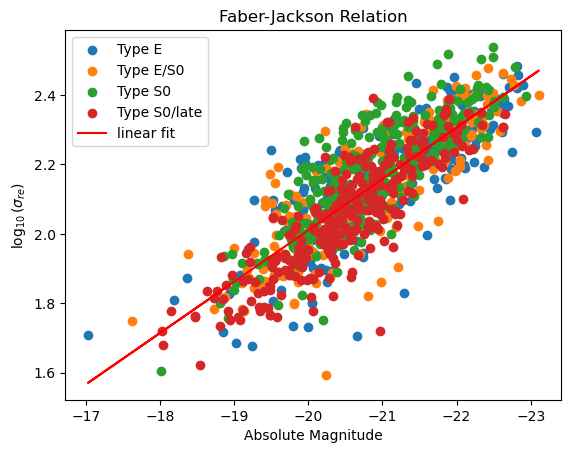

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

skiprow, catid, type, sigma_re, m_r = np.loadtxt('cleaned_data_mr_1.5.txt', unpack=True) # Data saved as array in text file
yvalues = np.log10(sigma_re)
xvalues = m_r   # m_r

# defining x and y variables, and all the type lables 
M = xvalues
sigma = yvalues
E = type == 0.0
E_S0 = type == 0.5
S0 = type == 1.0
S0_late = type == 1.5

# plotting early type galaxies
plt.scatter(xvalues[E], yvalues[E], label="Type E")
plt.scatter(xvalues[E_S0], yvalues[E_S0], label="Type E/S0")
plt.scatter(xvalues[S0], yvalues[S0], label="Type S0")
plt.scatter(xvalues[S0_late], yvalues[S0_late], label="Type S0/late")


# defining relationship
def relation(Mag, k, b):
    return k * Mag + b

# finding the parameters and covariance matrix form the fit
params, covariance = curve_fit(relation, M, sigma)

# defining what k is
k = params[0] 
b = params[1]

# finding the linear fit
fit = relation(M,k,b)
plt.plot(M, fit, color="red", label="linear fit") #show linear regression as red line

plt.gca().invert_xaxis() #invert x axis to match the convention of absolute magnitude (brighter objects have lower magnitudes)

plt.legend(loc="best")
plt.title("Faber-Jackson Relation")
plt.xlabel(r"Absolute Magnitude")
plt.ylabel(r"$\log_{10}(\sigma_{re})$")
plt.show()

In [76]:
# finding the value of R^2 from defintion -> checking to see if linear fit is valid for this data set
SS_res = np.sum((sigma - fit)**2)
SS_tot = np.sum((sigma - np.mean(sigma))**2)
R2 = 1- SS_res/SS_tot

# fidning the value of r from R^2
corr_coef = np.sqrt(R2)

print("k =", k)
print("R^2 =", R2)
print("r=", corr_coef)
print("SS_res=", SS_res)
print("SS_tot=", SS_tot)

k = -0.14793570713298454
R^2 = 0.6811491804390268
r= 0.8253176239721449
SS_res= 9.874541133331979
SS_tot= 30.969157134136488


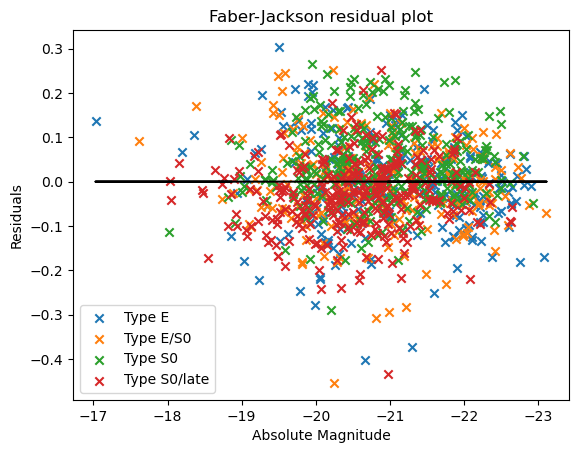

In [79]:
# finding the difference between the data and the fit
res = sigma - fit

# plotting each type's residual and a line to show where zero is
plt.scatter(M[E], res[E], label="Type E", marker = 'x')
plt.scatter(M[E_S0], res[E_S0], label="Type E/S0", marker = 'x')
plt.scatter(M[S0], res[S0], label="Type S0", marker = 'x')
plt.scatter(M[S0_late], res[S0_late], label="Type S0/late", marker = 'x')
plt.gca().invert_xaxis()
plt.plot(M, fit - fit,color="black")
plt.xlabel(r"Absolute Magnitude")
plt.ylabel(r"Residuals")
plt.title("Faber-Jackson residual plot")
plt.legend()

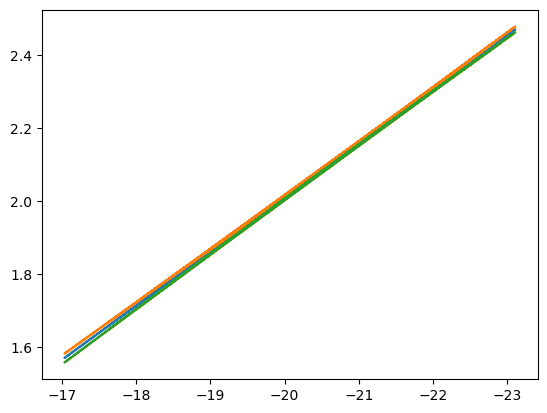

In [71]:
# defining the linear realtionship 
def relation(Mag, k, b):
    return k * Mag + b
    
# finding the obtained paramters from the linear fit and and the covarance of these constants
params, covariance = curve_fit(relation, M, sigma)

k = params[0]
b = params[1]

# finding the variance of the linear fit, dervied from the convariance matrix you get from the linear fit
variance =  M**2 * covariance[0,0] + covariance[1,1] + 2*M*covariance[0,1]

# finding sigma from the linear
sigma_fit = np.sqrt(variance)

# defining the fit and the max and min fit, which is one standard deviation on either side of the predicted fit
fit = relation(M,k,b)
max_fit = fit + sigma_fit
min_fit = fit - sigma_fit

#plotting fit, max and min fit
plt.plot(M, fit)
plt.plot(M, max_fit)
plt.plot(M, min_fit)
plt.gca().invert_xaxis()
plt.fill_between(M, min_fit, max_fit, color="orange", alpha = 0.5)


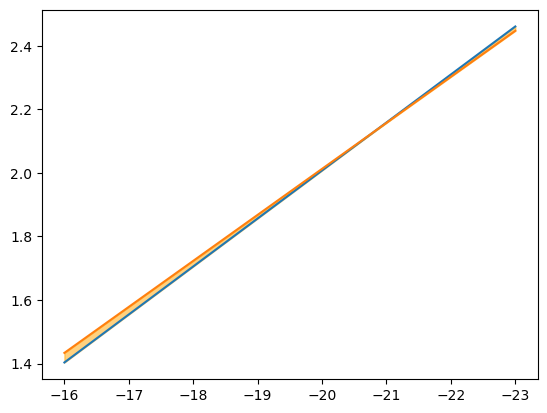

In [73]:
# this was an earlier version of the data analysis 

err = np.sqrt(np.diag(covariance))
xfit = np.arange(-23,-15)
ymin = (k - err[0])*xfit + (b - err[1])
ymax = (k + err[0])*xfit + (b + err[1])
yfit = k*xfit + b

plt.fill_between(xfit, ymin, ymax, color="orange", alpha = 0.5)
plt.plot(xfit, ymin)
plt.plot(xfit, ymax)
plt.gca().invert_xaxis()

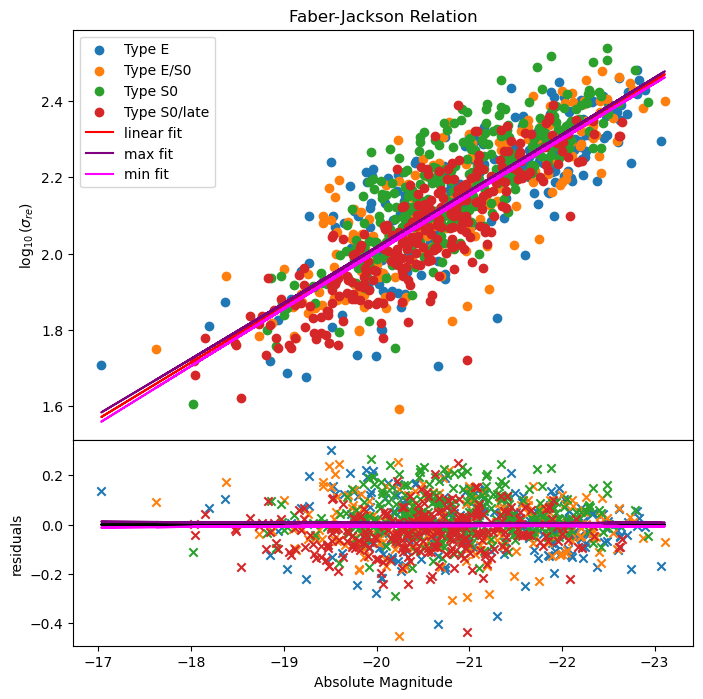

In [77]:
# creating two plots on top of each other
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), gridspec_kw={'height_ratios': [2, 1]})

# plotting the early type 
ax1.scatter(xvalues[E], yvalues[E], label="Type E")
ax1.scatter(xvalues[E_S0], yvalues[E_S0], label="Type E/S0")
ax1.scatter(xvalues[S0], yvalues[S0], label="Type S0")
ax1.scatter(xvalues[S0_late], yvalues[S0_late], label="Type S0/late")

# plotting the linear regression, and the max and min fit of this
ax1.plot(M, fit, color="red", label="linear fit")
ax1.plot(M, max_fit, color = "purple", label = "max fit")
ax1.plot(M, min_fit, color = "magenta", label = "min fit")

# plotting the legend and labeling the graph
ax1.legend(loc="best")
ax1.set_title("Faber-Jackson Relation")
ax2.set_xlabel(r"Absolute Magnitude")
ax1.set_ylabel(r"$\log_{10}(\sigma_{re})$")

# plotting the residuals for each early type 
ax2.scatter(M[E], res[E], label="Type E", marker = 'x')
ax2.scatter(M[E_S0], res[E_S0], label="Type E/S0", marker = 'x')
ax2.scatter(M[S0], res[S0], label="Type S0", marker = 'x')
ax2.scatter(M[S0_late], res[S0_late], label="Type S0/late", marker = 'x')

# labeling and plotting the residuals plot, including the max and min fit
ax2.set_ylabel(r"residuals")
ax2.plot(M, fit - fit,color="black")
ax2.plot(M, max_fit - fit, color = "purple", label = "max fit")
ax2.plot(M, min_fit - fit, color = "magenta", label = "min fit")

# inverting both axis to match the convention for the graphs
ax1.invert_xaxis()
ax2.invert_xaxis()

# making the graphs touch with no gaps between
plt.subplots_adjust(hspace=0)

[-9.   0.   0.5  1.   1.5  2.   2.5  3.   5. ]


Text(0, 0.5, '$\\log_{10}(\\sigma_{re})$')

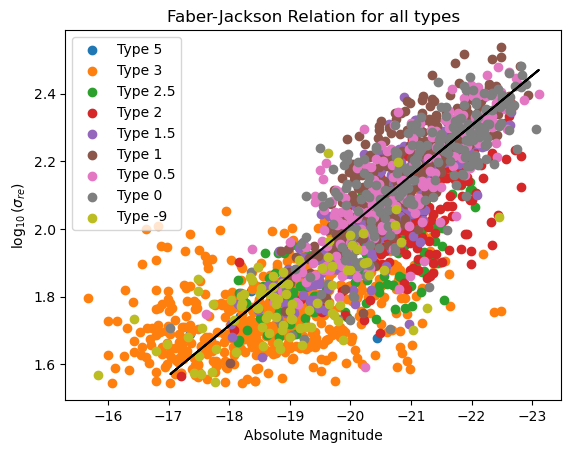

In [63]:
skiprow, catid, type, sigma_re, m_r = np.loadtxt('cleaned_data_mr_all.txt', unpack=True) #importing the entire data set

sigma = np.log10(sigma_re) # taking the log of each sigma value
M1 = m_r   # m_r

# plotting each type on the faber jackson relation
plt.scatter(M1[type == 5], sigma[type == 5], label="Type 5")
plt.scatter(M1[type == 3], sigma[type == 3], label="Type 3")
plt.scatter(M1[type == 2.5], sigma[type == 2.5], label="Type 2.5")
plt.scatter(M1[type == 2], sigma[type == 2], label="Type 2")
plt.scatter(M1[type == 1.5], sigma[type == 1.5], label="Type 1.5")
plt.scatter(M1[type == 1], sigma[type == 1], label="Type 1")
plt.scatter(M1[type == 0.5], sigma[type == 0.5], label="Type 0.5")
plt.scatter(M1[type == 0], sigma[type == 0], label="Type 0")
plt.scatter(M1[type == -9], sigma[type == -9], label="Type -9")
plt.plot(M, fit, color = "black")

#checking all the types are accounted for
print(np.unique(type))

# labeling, ploting and inverting axis for plot
plt.gca().invert_xaxis()
plt.legend(loc="best")
plt.title("Faber-Jackson Relation for all types")
plt.xlabel(r"Absolute Magnitude")
plt.ylabel(r"$\log_{10}(\sigma_{re})$")